# Práctica Tema 4.1 — Pipeline operativo de inferencia

**Maestría en Inteligencia Artificial · Visión Inteligente · Unidad IV · Actividad 4.1**
**Alumno:** David Díaz de la Cruz

---

## ¿Qué es un pipeline operativo?

En la Actividad 3.3 entrenamos una CNN que reconoce **círculos, cuadrados y triángulos**. Ese modelo vive en un
notebook: para usarlo hay que ejecutar celdas en orden, con los datos ya cargados en memoria.

Un **pipeline operativo** es el "chasis" que permite usar el modelo **fuera del laboratorio**: recibe imágenes
nuevas de cualquier origen, las prepara, consulta al modelo, interpreta la respuesta y entrega un resultado,
**sin intervención humana**, registrando todo lo que pasa.

| Notebook (Unidad 3) | Script de producción (este pipeline) |
|---|---|
| Para **explorar** y aprender | Para **operar** todos los días |
| Celdas en cualquier orden | Se ejecuta de principio a fin, solo |
| Rutas escritas a mano | Rutas y parámetros en `config/config.yaml` |
| Si algo falla, se ve el error y se corrige | Si algo falla, se **registra** y se sigue con lo demás |
| Una imagen a la vez, desde memoria | Imagen, carpeta completa o video/cámara |

## Las fases y dónde está cada una en el proyecto

```
            ┌──────────┐   ┌────────────────┐   ┌───────────┐   ┌──────────────────┐   ┌──────────┐
 imagen ──► │ ENTRADA  │──►│ PREPROCESAMIENTO│──►│ INFERENCIA│──►│ POSPROCESAMIENTO │──►│  SALIDA  │──► JSON / CSV
 carpeta    │ (Fase 3) │   │    (Fase 4)     │   │ (Fase 5-6)│   │     (Fase 7)     │   │ (Fase 8) │    imagen / video
 video      └──────────┘   └────────────────┘   └───────────┘   └──────────────────┘   └──────────┘
                    └───────────────────── registro y logs (Fase 9) ─────────────────────────┘
```

| Fase | ¿Qué hace? | Archivo |
|---|---|---|
| 1. Preparación del modelo | Versiona el modelo y crea su ficha técnica | `herramientas/preparar_modelo.py` → `models/` |
| 2. Entorno de ejecución | Dependencias con versión fija | `requirements.txt` |
| 3. Ingesta de datos | Lee imagen/carpeta/video y **valida** | `src/entrada.py` |
| 4. Preprocesamiento | Gris → 64×64 → /255 (**igual que al entrenar**) | `src/preprocesamiento.py` |
| 5. Carga del modelo | Huella digital, forma de entrada, prueba de integridad | `src/modelo.py` |
| 6. Inferencia | *Forward-pass* medido en milisegundos | `src/modelo.py` |
| 7. Posprocesamiento | Clase, confianza, umbral, suavizado en video | `src/postprocesamiento.py` |
| 8. Salida | Consola, JSON, CSV, imagen y video anotados | `src/salida.py` |
| 9. Registro | Log por ejecución + bitácora de auditoría | `src/registro.py` |
| 10. Preparación para empaquetado | Estructura de carpetas, script de inicio | `src/pipeline_operativo.py` |

> Este notebook **no copia** el código del pipeline: lo **importa** desde `src/`. Así se comprueba que el
> mismo código que se usará en producción (y después en el contenedor Docker de la Actividad 4.2) es el que se analiza aquí.

## 0. Preparación

Nos colocamos en la carpeta raíz del proyecto y agregamos `src/` a la ruta de Python para poder importar los módulos.

In [1]:
import os, sys, json, time, shutil
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # menos mensajes de TensorFlow (también en los subprocesos)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)                                  # todas las rutas serán relativas a la raíz
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

# Módulos del pipeline (los mismos que usa el script de producción)
from configuracion import cargar_config
from entrada import leer_imagen, ErrorEntrada
from preprocesamiento import a_escala_de_grises, preprocesar, crear_lote
from modelo import cargar_modelo, inferir, ErrorModelo
from pipeline_operativo import PipelineOperativo

FIG = Path("notebooks/figuras_4_1"); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
import tensorflow as tf, keras
print("Raíz del proyecto:", RAIZ)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| OpenCV", cv2.__version__)

I0000 00:00:1793473947.173271    5038 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793473948.352962    5038 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Raíz del proyecto: /home/claude/maestria_modelo_vision_inteligente
TensorFlow 2.21.0 | Keras 3.15.1 | OpenCV 5.0.0


## 1. Fases 1, 2 y 10: el modelo empaquetado y la estructura del proyecto

**Fase 1 — preparación del modelo.** El script `herramientas/preparar_modelo.py` toma el modelo final de la 3.3
y genera tres archivos en `models/`:

* `modelo_figuras_v1.keras`: el modelo con **versión en el nombre**. El formato `.keras` es el formato nativo de
  Keras 3: un archivo comprimido con la arquitectura, los pesos y la configuración. Es el sucesor recomendado del `.h5`.
* `clases.txt`: el nombre de cada salida de la red, **en el mismo orden** del entrenamiento.
* `model_card.json`: la **ficha técnica**. Dice qué entrada espera el modelo, cómo se preprocesa, qué métricas obtuvo
  y su **huella SHA-256**.

**Congelación de pesos:** el modelo se carga con `compile=False` y siempre se llama con `training=False`. Así ningún
peso cambia y las capas que solo sirven para entrenar (aumento de datos y Dropout) quedan **apagadas**.

In [2]:
tarjeta = json.loads(Path("models/model_card.json").read_text(encoding="utf-8"))
print(json.dumps({k: tarjeta[k] for k in ["nombre", "version", "archivo", "parametros", "entrada",
                                          "clases", "metricas_prueba", "versiones"]},
                 ensure_ascii=False, indent=2))
print("SHA-256:", tarjeta["sha256"])
print("\nCapas que solo actúan al ENTRENAR (inactivas en inferencia):", tarjeta["capas_solo_entrenamiento"])

{
  "nombre": "Clasificador de figuras geométricas",
  "version": "1.0.0",
  "archivo": "modelo_figuras_v1.keras",
  "parametros": 285699,
  "entrada": {
    "forma": [
      64,
      64,
      1
    ],
    "color": "escala de grises (1 canal)",
    "normalizacion": "pixel / 255  ->  rango [0, 1]",
    "dominio": "figura oscura sobre fondo claro, una figura por imagen"
  },
  "clases": [
    "circulo",
    "cuadrado",
    "triangulo"
  ],
  "metricas_prueba": {
    "exactitud": 0.9944,
    "perdida": 0.0314,
    "macro_f1": 0.9944,
    "imagenes": 180
  },
  "versiones": {
    "tensorflow": "2.21.0",
    "keras": "3.15.1"
  }
}
SHA-256: 06b88942d630dc4abc1fa85d66c28355f31dca878af748b0960a2ad4a4a1cf75

Capas que solo actúan al ENTRENAR (inactivas en inferencia): ['random_flip_1', 'random_rotation_1', 'random_translation_1']


In [3]:
def arbol(carpeta, prefijo="", max_archivos=4, ignorar=("__pycache__", "outputs", "dataset_figuras", ".git", ".ipynb_checkpoints", "figuras_4_1")):
    # Dibuja la estructura de carpetas (mostrando solo algunos archivos por carpeta)
    elementos = sorted([p for p in Path(carpeta).iterdir() if p.name not in ignorar and not p.name.startswith(".")],
                       key=lambda p: (p.is_file(), p.name))
    carpetas = [p for p in elementos if p.is_dir()]
    archivos = [p for p in elementos if p.is_file()]
    for p in carpetas:
        print(f"{prefijo}├── {p.name}/")
        arbol(p, prefijo + "│   ", max_archivos, ignorar)
    for p in archivos[:max_archivos]:
        print(f"{prefijo}├── {p.name}")
    if len(archivos) > max_archivos:
        print(f"{prefijo}└── ... ({len(archivos) - max_archivos} archivos más)")

print("maestria_modelo_vision_inteligente/")
arbol(".")

maestria_modelo_vision_inteligente/
├── config/
│   ├── config.yaml
├── data/
│   ├── conjunto_prueba/
│   │   ├── circulo/
│   │   │   ├── circulo_0004.png
│   │   │   ├── circulo_0008.png
│   │   │   ├── circulo_0013.png
│   │   │   ├── circulo_0014.png
│   │   │   └── ... (56 archivos más)
│   │   ├── cuadrado/
│   │   │   ├── cuadrado_0004.png
│   │   │   ├── cuadrado_0034.png
│   │   │   ├── cuadrado_0043.png
│   │   │   ├── cuadrado_0046.png
│   │   │   └── ... (56 archivos más)
│   │   ├── triangulo/
│   │   │   ├── triangulo_0000.png
│   │   │   ├── triangulo_0002.png
│   │   │   ├── triangulo_0012.png
│   │   │   ├── triangulo_0013.png
│   │   │   └── ... (56 archivos más)
│   ├── ejemplos/
│   │   ├── fuera_de_dominio/
│   │   │   ├── circulo_invertida.png
│   │   │   ├── circulo_mano_alzada_1.png
│   │   │   ├── circulo_mano_alzada_2.png
│   │   │   ├── cuadrado_invertida.png
│   │   │   └── ... (5 archivos más)
│   │   ├── invalidos/
│   │   │   ├── corrupta.png
│   │   │  

**Fase 2 — entorno.** `requirements.txt` fija la **versión exacta** de cada librería (`tensorflow-cpu==2.21.0`,
`keras==3.15.1`, ...). Si otra persona instala con versiones distintas, el modelo podría no cargar o dar números
ligeramente diferentes. Fijarlas es lo que hace al pipeline **reproducible en otra máquina**.

La configuración vive en `config/config.yaml`, no en el código:

In [4]:
cfg = cargar_config()
print(json.dumps(cfg, ensure_ascii=False, indent=2))

{
  "modelo": {
    "ruta": "models/modelo_figuras_v1.keras",
    "tarjeta": "models/model_card.json",
    "clases": "models/clases.txt",
    "verificar_hash": true
  },
  "preprocesamiento": {
    "alto": 64,
    "ancho": 64,
    "canales": 1,
    "divisor": 255.0
  },
  "entrada": {
    "extensiones_validas": [
      ".png",
      ".jpg",
      ".jpeg",
      ".bmp",
      ".tif",
      ".tiff"
    ],
    "tamano_minimo": 16
  },
  "inferencia": {
    "tamano_lote": 32
  },
  "postprocesamiento": {
    "umbral_confianza": 0.8,
    "top_k": 3
  },
  "tiempo_real": {
    "fps_objetivo": 15,
    "ventana_suavizado": 5
  },
  "salida": {
    "carpeta": "outputs"
  }
}


## 2. Fase 5: carga del modelo con validaciones

`cargar_modelo()` no solo "abre el archivo". Hace cinco comprobaciones, porque en producción **un modelo equivocado
que responde es peor que un modelo que no carga**:

1. ¿Existe el archivo? 2. ¿Su huella SHA-256 coincide con la ficha técnica? 3. ¿La red espera una entrada de 64×64×1?
4. ¿Hay GPU o se usará CPU? 5. **Prueba de integridad**: una inferencia con una imagen en blanco debe devolver
3 probabilidades que sumen 1. Esta primera llamada además "calienta" el modelo: TensorFlow prepara sus operaciones
la primera vez, y así esa demora no contamina las mediciones de tiempo.

In [5]:
pipe = PipelineOperativo(modo="notebook")

13:12:29 | INFO    | === Ejecución 20261031-131229_notebook ===


13:12:29 | INFO    | Huella SHA-256 verificada (06b88942d630...)


13:12:29 | INFO    | Modelo cargado: modelo_figuras_v1.keras v1.0.0 en 0.19 s


13:12:29 | INFO    | Dispositivo de ejecución: CPU


13:12:29 | INFO    | Prueba de integridad correcta (salida (1, 3), suma de probabilidades = 1.000)


### ¿Qué pasa si alguien altera el modelo?

Copiamos el modelo y cambiamos **un solo byte** del archivo. Visualmente es "el mismo" archivo, pero la huella cambia
y el pipeline se niega a usarlo.

In [6]:
copia = Path("outputs/tmp_modelo_alterado.keras")
copia.parent.mkdir(exist_ok=True)
datos = bytearray(Path("models/modelo_figuras_v1.keras").read_bytes())
datos[-100] ^= 0xFF                           # invertimos los bits de UN byte
copia.write_bytes(datos)
try:
    cargar_modelo(copia, "models/model_card.json", (64, 64, 1))
except ErrorModelo as e:
    print("ErrorModelo ->", e)
copia.unlink()

ErrorModelo -> La huella SHA-256 del modelo NO coincide con model_card.json: el archivo fue modificado o es otra versión.


## 3. Fases 3 y 4: entrada y preprocesamiento, paso a paso

La regla más importante del pipeline: **la imagen debe llegar al modelo exactamente como llegaban las imágenes de
entrenamiento**. En la Actividad 3.3 se hizo:

```python
Image.open(archivo).convert("L")      # escala de grises
imgs.astype("float32") / 255.0        # valores entre 0 y 1
imgs[..., np.newaxis]                 # forma (64, 64, 1)
```

En producción las imágenes llegan **a color y de cualquier tamaño**, así que `preprocesar()` agrega la conversión
de tamaño. Veamos el recorrido de una imagen de 320×320 a color:

Cruda:         forma (320, 320, 3), tipo uint8, valores 0..255
Gris:          forma (320, 320)
Redimensionada: forma (64, 64)
Normalizada:   forma (64, 64, 1), tipo float32, valores 0.22..0.93
Lote:          forma (1, 64, 64, 1)   <- (imágenes, alto, ancho, canales)

Diferencia máxima OpenCV vs PIL en la conversión a gris: 0 niveles de 255


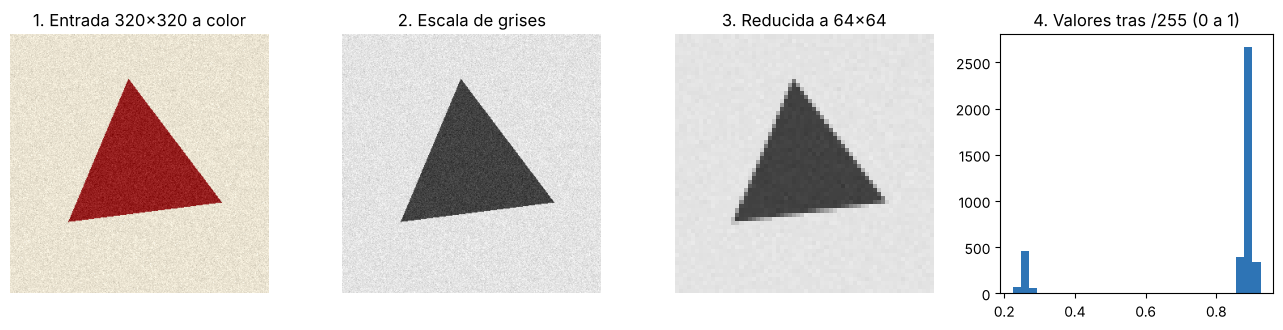

In [7]:
ruta = "data/ejemplos/variaciones/triangulo_color_320px.png"
cruda = leer_imagen(ruta, cfg["entrada"]["extensiones_validas"])        # Fase 3 (BGR, como la lee OpenCV)
gris = a_escala_de_grises(cruda)                                        # paso 1
pequena = cv2.resize(gris, (64, 64), interpolation=cv2.INTER_AREA)     # paso 2
x = preprocesar(cruda)                                                  # pasos 1+2+3+4 juntos
lote = crear_lote([x])

print(f"Cruda:         forma {cruda.shape}, tipo {cruda.dtype}, valores {cruda.min()}..{cruda.max()}")
print(f"Gris:          forma {gris.shape}")
print(f"Redimensionada: forma {pequena.shape}")
print(f"Normalizada:   forma {x.shape}, tipo {x.dtype}, valores {x.min():.2f}..{x.max():.2f}")
print(f"Lote:          forma {lote.shape}   <- (imágenes, alto, ancho, canales)")

# Comprobación: ¿la conversión a gris de OpenCV es igual a la de PIL (.convert("L")) usada al entrenar?
gris_pil = np.array(Image.open(ruta).convert("L"))
print("\nDiferencia máxima OpenCV vs PIL en la conversión a gris:", np.abs(gris_pil.astype(int) - gris.astype(int)).max(), "niveles de 255")

fig, ejes = plt.subplots(1, 4, figsize=(13, 3.4))
ejes[0].imshow(cv2.cvtColor(cruda, cv2.COLOR_BGR2RGB)); ejes[0].set_title("1. Entrada 320×320 a color")
ejes[1].imshow(gris, cmap="gray", vmin=0, vmax=255); ejes[1].set_title("2. Escala de grises")
ejes[2].imshow(pequena, cmap="gray", vmin=0, vmax=255); ejes[2].set_title("3. Reducida a 64×64")
ejes[3].hist(x.ravel(), bins=30, color="#2e74b5"); ejes[3].set_title("4. Valores tras /255 (0 a 1)")
for e in ejes[:3]: e.axis("off")
plt.tight_layout(); plt.savefig(FIG / "01_preprocesamiento.png", dpi=150); plt.show()

**Detalle:** OpenCV lee las imágenes en orden **BGR** (azul, verde, rojo), no RGB. Por eso la conversión a gris usa
`COLOR_BGR2GRAY`, que aplica la misma fórmula que PIL (`0.299·R + 0.587·G + 0.114·B`). La comprobación muestra
diferencia **cero**: ambos producen exactamente la misma imagen en gris.

## 4. Modo **imagen**: el pipeline desde la terminal

Así se usaría en producción. Cada ejecución deja sus resultados en `outputs/<run_id>/`.

In [8]:
!{sys.executable} src/pipeline_operativo.py --modo imagen --entrada data/ejemplos/variaciones/cuadrado_transparente.png

I0000 00:00:1793473950.285654    5069 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793473951.403054    5069 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


13:12:32 | INFO    | === Ejecución 20261031-131232_imagen ===
13:12:32 | INFO    | Huella SHA-256 verificada (06b88942d630...)


13:12:32 | INFO    | Modelo cargado: modelo_figuras_v1.keras v1.0.0 en 0.20 s
13:12:32 | INFO    | Dispositivo de ejecución: CPU


13:12:32 | INFO    | Prueba de integridad correcta (salida (1, 3), suma de probabilidades = 1.000)
13:12:32 | INFO    | cuadrado_transparente.png: cuadrado (100.0%) [ok] en 13.8 ms


13:12:32 | INFO    | Resultados en: /home/claude/maestria_modelo_vision_inteligente/outputs/20261031-131232_imagen

RESULTADO: cuadrado  (100.00%)  [ok]
cuadrado=100.00%  circulo=0.00%  triangulo=0.00%


{
  "archivo": "cuadrado_transparente.png",
  "clase": "cuadrado",
  "confianza": 1.0,
  "estado": "ok",
  "top": [
    {
      "clase": "cuadrado",
      "prob": 1.0
    },
    {
      "clase": "circulo",
      "prob": 0.0
    },
    {
      "clase": "triangulo",
      "prob": 0.0
    }
  ],
  "inferencia_ms": 11.1,
  "total_ms": 13.78
}


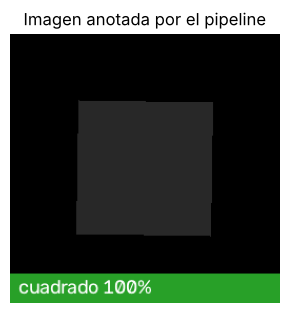

In [9]:
ultima = sorted(Path("outputs").glob("*_imagen"))[-1]
print(json.dumps(json.loads((ultima / "resultado.json").read_text(encoding="utf-8")), ensure_ascii=False, indent=2))
anotada = cv2.imread(str(next(ultima.glob("*_anotada.png"))))
plt.figure(figsize=(3.5, 3.5)); plt.imshow(cv2.cvtColor(anotada, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("Imagen anotada por el pipeline"); plt.show()

Esta imagen tiene **fondo transparente** (PNG con canal alfa). Si se convirtiera a gris ignorando la transparencia,
el fondo quedaría **negro** y la figura desaparecería. El pipeline pinta lo transparente de blanco, porque en el
dataset el fondo siempre es claro.

## 5. Modo **lote** y prueba de paridad con la Actividad 3.3

**Pregunta clave:** ¿el pipeline da **los mismos resultados** que el notebook de entrenamiento? Si no, algo en el
preprocesamiento es distinto. Procesamos las **mismas 180 imágenes de prueba** de la 3.3 (`data/conjunto_prueba/`,
una subcarpeta por clase, así el pipeline calcula la exactitud por sí solo).

In [10]:
!{sys.executable} src/pipeline_operativo.py --modo lote --entrada data/conjunto_prueba --lote 32

I0000 00:00:1793473954.138914    5081 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793473955.308304    5081 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


13:12:36 | INFO    | === Ejecución 20261031-131236_lote ===
13:12:36 | INFO    | Huella SHA-256 verificada (06b88942d630...)


13:12:36 | INFO    | Modelo cargado: modelo_figuras_v1.keras v1.0.0 en 0.18 s
13:12:36 | INFO    | Dispositivo de ejecución: CPU


13:12:36 | INFO    | Prueba de integridad correcta (salida (1, 3), suma de probabilidades = 1.000)
13:12:36 | INFO    | Modo lote: 180 archivos en 'data/conjunto_prueba', lotes de 32


13:12:37 | INFO    | Procesadas 180 | errores 0 | baja confianza 8 | 987.5 img/s | exactitud 99.44%
13:12:37 | INFO    | Resultados en: /home/claude/maestria_modelo_vision_inteligente/outputs/20261031-131236_lote


In [11]:
run_lote = sorted(Path("outputs").glob("*_lote"))[-1]
res = pd.read_csv(run_lote / "resultados.csv")
resumen_lote = json.loads((run_lote / "resumen.json").read_text(encoding="utf-8"))
metricas_33 = json.loads(Path("entrenamiento/resultados/metricas_finales.json").read_text(encoding="utf-8"))

print(f"Exactitud en la Actividad 3.3 (notebook): {metricas_33['aumento']['prueba']['exactitud']:.2%}")
print(f"Exactitud con el pipeline operativo:     {resumen_lote['exactitud']:.2%}")

# Paridad a nivel de probabilidades: cargamos las imágenes EXACTAMENTE como en la 3.3 y comparamos
clases = pipe.clases
X_33 = np.array([np.array(Image.open(Path("data/conjunto_prueba") / a).convert("L")) for a in res["archivo"]])
y_real = np.array([clases.index(c) for c in res["clase_real"]])
prob_33 = np.asarray(pipe.modelo(X_33.astype("float32")[..., None] / 255.0, training=False))
prob_pipe = res[[f"p_{c}" for c in clases]].to_numpy()
print(f"Diferencia máxima de probabilidad (3.3 vs pipeline): {np.abs(prob_33 - prob_pipe).max():.5f}  "
      "(el CSV guarda 4 decimales)")
print("\nImágenes mal clasificadas:")
print(res[~res["correcto"]][["archivo", "clase", "confianza", "clase_real"]].to_string(index=False))

Exactitud en la Actividad 3.3 (notebook): 99.44%
Exactitud con el pipeline operativo:     99.44%


Diferencia máxima de probabilidad (3.3 vs pipeline): 0.00005  (el CSV guarda 4 decimales)

Imágenes mal clasificadas:
                   archivo     clase  confianza clase_real
cuadrado/cuadrado_0347.png triangulo     0.6524   cuadrado


**Resultado:** la exactitud es idéntica (99.44 %, 179 de 180) y las probabilidades coinciden hasta el redondeo.
El pipeline reproduce fielmente al modelo de la Unidad 3: **la paridad está comprobada**.

## 6. Experimento: ¿qué pasa si el preprocesamiento NO es idéntico?

Este es el error más común (y más peligroso) al llevar un modelo a producción: **el programa no falla**, el modelo
sigue respondiendo con aparente seguridad, pero las respuestas son malas. Probamos el mismo modelo con las mismas
180 imágenes, cambiando solo un detalle del preprocesamiento.

preprocesamiento,exactitud,confianza_media
"Correcto: gris, 64×64, /255",99.44%,97.68%
Olvidar dividir entre 255,97.78%,100.00%
"Normalizar a [-1, 1] (como en la 2.3)",98.89%,98.44%
Colores invertidos (fondo oscuro),91.67%,91.08%
Cámara de baja resolución (16×16),90.00%,80.55%


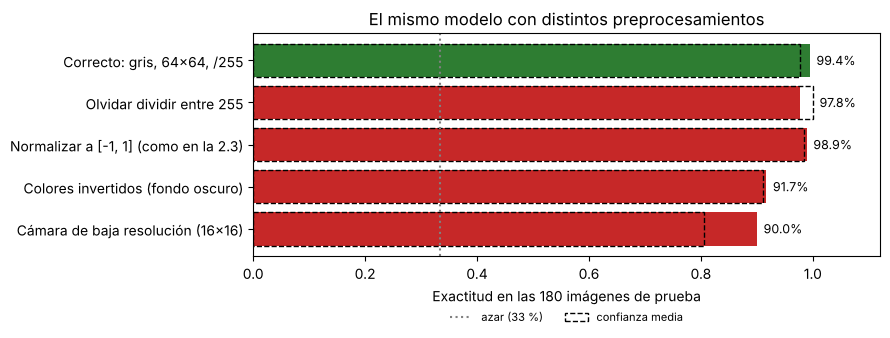

In [12]:
def evaluar(x):
    p = np.asarray(pipe.modelo(x.astype("float32"), training=False))
    return (p.argmax(1) == y_real).mean(), p.max(1).mean()

def baja_resolucion(img, lado=16):
    # Simula una cámara de baja resolución: se reduce a 16x16 y se vuelve a ampliar
    return cv2.resize(cv2.resize(img, (lado, lado), interpolation=cv2.INTER_AREA), (64, 64), interpolation=cv2.INTER_LINEAR)

X = X_33.astype("float32")[..., None]
variantes = {
    "Correcto: gris, 64×64, /255": X / 255.0,
    "Olvidar dividir entre 255": X,
    "Normalizar a [-1, 1] (como en la 2.3)": X / 127.5 - 1.0,
    "Colores invertidos (fondo oscuro)": (255.0 - X) / 255.0,
    "Cámara de baja resolución (16×16)": np.array([baja_resolucion(i) for i in X_33])[..., None] / 255.0,
}
filas = []
for nombre, xv in variantes.items():
    exa, conf = evaluar(xv)
    filas.append({"preprocesamiento": nombre, "exactitud": exa, "confianza_media": conf})
tabla_pre = pd.DataFrame(filas)
display(tabla_pre.style.format({"exactitud": "{:.2%}", "confianza_media": "{:.2%}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 3.6))
colores = ["#2e7d32"] + ["#c62828"] * (len(tabla_pre) - 1)
ax.barh(tabla_pre["preprocesamiento"], tabla_pre["exactitud"], color=colores)
ax.barh(tabla_pre["preprocesamiento"], tabla_pre["confianza_media"], fill=False, edgecolor="black", ls="--", label="confianza media")
for i, (v, c) in enumerate(zip(tabla_pre["exactitud"], tabla_pre["confianza_media"])):
    ax.text(max(v, c) + 0.012, i, f"{v:.1%}", va="center", fontsize=9)
ax.axvline(1/3, color="gray", ls=":", label="azar (33 %)")
ax.set_xlim(0, 1.12); ax.invert_yaxis(); ax.set_xlabel("Exactitud en las 180 imágenes de prueba")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8, frameon=False)
ax.set_title("El mismo modelo con distintos preprocesamientos")
plt.tight_layout(); plt.savefig(FIG / "02_error_preprocesamiento.png", dpi=150); plt.show()

**Interpretación:**
* Este modelo resultó **más tolerante** de lo esperado: olvidar `/255` solo baja la exactitud de 99.4 % a 97.8 %. La red
  aprendió a reconocer *formas* (bordes y esquinas), y las capas ReLU y MaxPooling conservan esas formas aunque los
  valores se multipliquen por 255. No hay que generalizarlo: en una red preentrenada como la MobileNetV2 de la 2.3, que
  espera exactamente el rango [−1, 1], el mismo descuido suele ser mucho más grave.
* Lo preocupante es que **ningún error es visible**: el programa no falla y la confianza no avisa. Sin `/255` la red
  pierde exactitud y **aumenta** su confianza a 100 %. Con colores invertidos o con baja resolución pierde de 8 a 9
  puntos de exactitud, y la confianza baja apenas lo mismo.
* En un sistema real esos puntos son errores silenciosos día tras día. Por eso el preprocesamiento vive en **un solo
  módulo** (`src/preprocesamiento.py`) que reproduce la 3.3, la ficha técnica documenta la normalización esperada y la
  prueba de paridad (sección 5) es obligatoria antes de desplegar.

## 7. Lote contra velocidad: ¿por qué procesar en lotes?

Procesar imágenes **juntas** aprovecha mejor el procesador: hay un costo fijo por cada llamada al modelo (preparar
operaciones, mover datos) que se reparte entre todas las imágenes del lote. Medimos solo la inferencia, con distintos
tamaños de lote, repitiendo 5 veces y tomando la mediana.

tamano_lote,imagenes_por_segundo,ms_por_lote,ms_por_imagen
1,93.650000,10.680000,10.680000
2,170.680000,11.720000,5.860000
4,315.750000,12.670000,3.170000
8,550.810000,14.210000,1.820000
16,894.660000,16.770000,1.120000
32,1364.500000,21.990000,0.730000
64,2059.350000,29.140000,0.490000
180,2801.510000,64.250000,0.360000


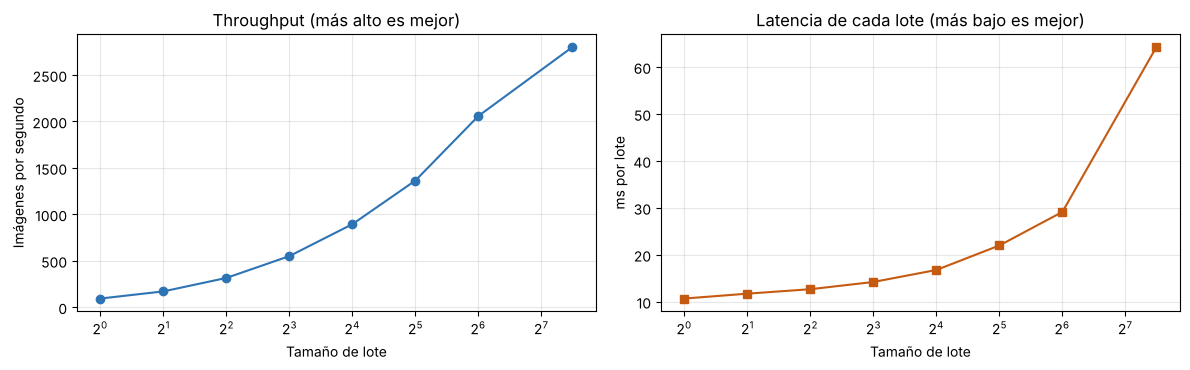

El mejor lote procesa 29.9 veces más imágenes por segundo que procesar de una en una.
Lotes de 32 -> solo inferencia: 1,364 img/s | pipeline completo (sección 5, con lectura de archivos): 988 img/s (72%)


In [13]:
X_pre = X / 255.0
filas = []
for tamano in [1, 2, 4, 8, 16, 32, 64, 180]:
    inferir(pipe.modelo, X_pre[:tamano])                     # calentamiento para este tamaño
    tiempos = []
    for _ in range(5):
        t0 = time.perf_counter()
        for i in range(0, len(X_pre), tamano):
            inferir(pipe.modelo, X_pre[i:i + tamano])
        tiempos.append(time.perf_counter() - t0)
    seg = np.median(tiempos)
    filas.append({"tamano_lote": tamano, "imagenes_por_segundo": len(X_pre) / seg,
                  "ms_por_lote": seg * 1000 / int(np.ceil(len(X_pre) / tamano)),
                  "ms_por_imagen": seg * 1000 / len(X_pre)})
tabla_lote = pd.DataFrame(filas)
display(tabla_lote.round(2).style.hide(axis="index"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(tabla_lote["tamano_lote"], tabla_lote["imagenes_por_segundo"], "o-", color="#2e74b5")
a1.set_xscale("log", base=2); a1.set_xlabel("Tamaño de lote"); a1.set_ylabel("Imágenes por segundo")
a1.set_title("Throughput (más alto es mejor)"); a1.grid(alpha=.3)
a2.plot(tabla_lote["tamano_lote"], tabla_lote["ms_por_lote"], "s-", color="#c55a11")
a2.set_xscale("log", base=2); a2.set_xlabel("Tamaño de lote"); a2.set_ylabel("ms por lote")
a2.set_title("Latencia de cada lote (más bajo es mejor)"); a2.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "03_lote_vs_throughput.png", dpi=150); plt.show()
mejora = tabla_lote["imagenes_por_segundo"].max() / tabla_lote["imagenes_por_segundo"].iloc[0]
print(f"El mejor lote procesa {mejora:.1f} veces más imágenes por segundo que procesar de una en una.")
solo_modelo = tabla_lote.loc[tabla_lote["tamano_lote"] == 32, "imagenes_por_segundo"].item()
print(f"Lotes de 32 -> solo inferencia: {solo_modelo:,.0f} img/s | pipeline completo (sección 5, con lectura de archivos): "
      f"{resumen_lote['throughput_img_s']:,.0f} img/s ({resumen_lote['throughput_img_s'] / solo_modelo:.0%})")

**Interpretación — el compromiso lote / latencia:**
* El **throughput** (imágenes por segundo) crece casi en proporción al tamaño del lote hasta 32: duplicar el lote casi
  duplica la velocidad, porque el costo fijo de cada llamada (~10 ms) se reparte. Después sigue creciendo, pero con
  **rendimientos decrecientes**: de 32 a 64 solo mejora alrededor de 20 %.
* La **latencia de cada lote** crece con su tamaño: con lotes grandes, la *primera* imagen tiene que esperar a que se
  junten y se procesen todas las demás.
* **El cuello de botella real no es el modelo.** El pipeline completo de la sección 5 (lotes de 32) procesa menos
  imágenes por segundo que la inferencia sola con el mismo lote: entre 50 y 75 % de esa velocidad en distintas
  ejecuciones (cifras de arriba). Entre una cuarta parte y la mitad del tiempo se va en **leer, decodificar y
  preprocesar archivos**.
* **Las mediciones de tiempo varían** entre ejecuciones (el equipo tiene 2 núcleos compartidos). Por eso aquí se toma la
  mediana de 5 repeticiones, y en la Actividad 4.2 las comparaciones de rendimiento se harán con repeticiones. Optimizar el modelo ayudaría poco; paralelizar la lectura
  ayudaría más.

Por eso hay dos modos: **lote** para procesar archivos acumulados (lo importante es terminar pronto el total) y
**tiempo real** con lote de 1 (lo importante es responder rápido a *cada* cuadro).

## 8. Robustez de la entrada: archivos variados, extraños e inválidos

Procesamos `data/ejemplos/`, que mezcla a propósito cinco tipos de archivo:

| Carpeta | Contenido | ¿Qué esperamos? |
|---|---|---|
| `nuevas/` | Figuras nuevas del mismo tipo que el dataset | Aciertos |
| `variaciones/` | Color, 320 px, JPG muy comprimido, PNG transparente, TIFF de 16 bits, imagen rectangular | Aciertos (si el preprocesamiento es robusto) |
| `fuera_de_dominio/` | Dibujos "a mano alzada" y figuras con colores invertidos | Desconocido: el modelo nunca vio esto |
| `sin_clase/` | Pentágono, hexágono, estrella, dos figuras juntas, fondo vacío | **No existe** respuesta correcta |
| `invalidos/` | Archivo corrupto, vacío, de texto, imagen de 8×8 | Rechazarse **sin detener** el pipeline |

In [14]:
resumen_ej = pipe.ejecutar_lote(Path("data/ejemplos"), tamano_lote=8, guardar_imagenes=True)
run_ej = pipe.carpeta_run

13:13:01 | INFO    | Modo lote: 32 archivos en 'data/ejemplos', lotes de 8


13:13:01 | WARNING | Se omite 'corrupta.png': archivo corrupto o no es una imagen válida


13:13:01 | WARNING | Se omite 'diminuta_8x8.png': imagen demasiado pequeña (8x8)


13:13:01 | WARNING | Se omite 'notas.txt': formato no soportado '.txt'


13:13:01 | WARNING | Se omite 'vacia.jpg': archivo vacío (0 bytes)


13:13:01 | INFO    | Procesadas 28 | errores 4 | baja confianza 1 | 193.2 img/s


13:13:01 | INFO    | Resultados en: /home/claude/maestria_modelo_vision_inteligente/outputs/20261031-131229_notebook


In [15]:
res_ej = pd.read_csv(run_ej / "resultados.csv")
res_ej.insert(0, "grupo", res_ej["archivo"].str.split("/").str[0])
res_ej["archivo"] = res_ej["archivo"].str.split("/").str[1]
display(res_ej[["grupo", "archivo", "clase", "confianza", "estado"]].style.hide(axis="index")
        .format({"confianza": "{:.1%}"})
        .map(lambda v: "background-color:#ffe0b2" if v == "baja_confianza" else "", subset=["estado"]))
print("Archivos rechazados (errores.csv):")
display(pd.read_csv(run_ej / "errores.csv").style.hide(axis="index"))

grupo,archivo,clase,confianza,estado
fuera_de_dominio,circulo_invertida.png,circulo,100.0%,ok
fuera_de_dominio,circulo_mano_alzada_1.png,circulo,100.0%,ok
fuera_de_dominio,circulo_mano_alzada_2.png,circulo,99.9%,ok
fuera_de_dominio,cuadrado_invertida.png,cuadrado,100.0%,ok
fuera_de_dominio,cuadrado_mano_alzada_1.png,cuadrado,93.4%,ok
fuera_de_dominio,cuadrado_mano_alzada_2.png,cuadrado,99.2%,ok
fuera_de_dominio,triangulo_invertida.png,triangulo,97.4%,ok
fuera_de_dominio,triangulo_mano_alzada_1.png,triangulo,99.8%,ok
fuera_de_dominio,triangulo_mano_alzada_2.png,triangulo,99.9%,ok
nuevas,circulo_1.png,circulo,99.9%,ok


Archivos rechazados (errores.csv):


archivo,error
invalidos/corrupta.png,archivo corrupto o no es una imagen válida
invalidos/diminuta_8x8.png,imagen demasiado pequeña (8x8)
invalidos/notas.txt,formato no soportado '.txt'
invalidos/vacia.jpg,archivo vacío (0 bytes)


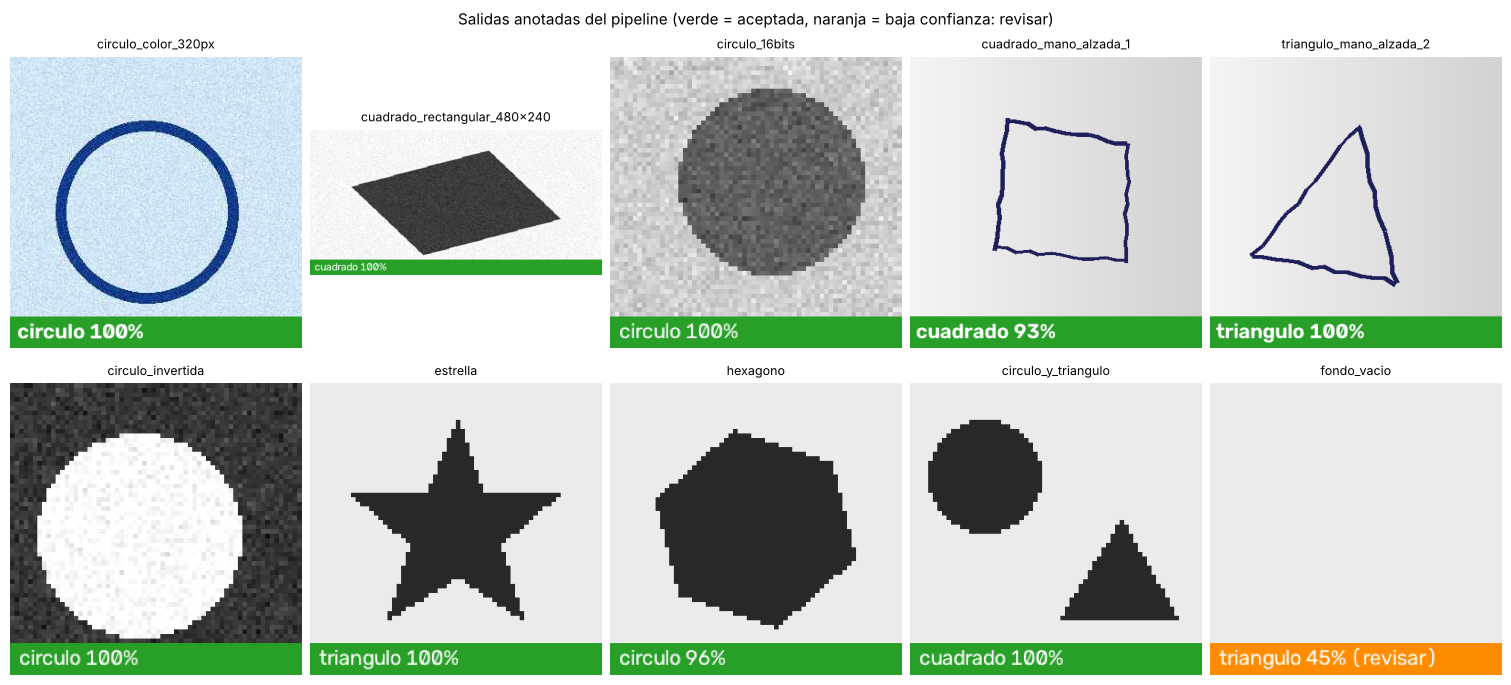

In [16]:
mostrar = ["circulo_color_320px", "cuadrado_rectangular_480x240", "circulo_16bits",
           "cuadrado_mano_alzada_1", "triangulo_mano_alzada_2", "circulo_invertida",
           "estrella", "hexagono", "circulo_y_triangulo", "fondo_vacio"]
fig, ejes = plt.subplots(2, 5, figsize=(15, 6.8), layout="constrained")
for eje, nombre in zip(ejes.ravel(), mostrar):
    img = cv2.imread(str(run_ej / "imagenes" / f"{nombre}.png"))
    eje.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); eje.set_title(nombre, fontsize=9); eje.axis("off")
plt.suptitle("Salidas anotadas del pipeline (verde = aceptada, naranja = baja confianza: revisar)", fontsize=11)
plt.savefig(FIG / "04_ejemplos_anotados.png", dpi=150); plt.show()

**Interpretación:**
* **Validación de entrada:** los cuatro archivos inválidos se rechazaron con un motivo claro y el lote **siguió**
  procesando las demás imágenes. En producción, un archivo dañado no debe detener la operación.
* **Variaciones de formato:** todas acertadas. El preprocesamiento convierte color, transparencia, 16 bits y
  cualquier tamaño a la entrada que el modelo conoce. La imagen rectangular se "aplasta" al llevarla a 64×64 y aun
  así se reconoce, aunque en otras figuras esa deformación podría cambiar la respuesta (un círculo aplastado es una elipse).
* **Fuera de dominio:** el modelo generalizó bien a dibujos a mano y a colores invertidos. Es un buen resultado del
  aumento de datos de la 3.3, aunque son pocos ejemplos y no prueban que siempre sea así.
* **Sin clase — la limitación importante:** la estrella sale como "triángulo" con ~100 % de confianza, y el pentágono
  como "cuadrado". Un clasificador de **clases cerradas** está obligado a elegir una de sus 3 clases y su *softmax*
  no sabe decir "no sé". El umbral de confianza solo atrapó el **fondo vacío**. Para resolverlo de verdad habría que
  entrenar una clase "otro" o usar técnicas de detección de entradas fuera de distribución.

## 9. Modo **tiempo real** (simulado)

Una cámara envía cuadros a un ritmo fijo (aquí **15 FPS**: un cuadro cada 66.7 ms) **esté listo o no el programa**.
El modo tiempo real simula ese reloj: si procesar un cuadro tarda más que su "presupuesto" de 66.7 ms, los cuadros que
llegaron mientras tanto **se pierden**, igual que con una cámara real.

El video `data/video/figuras.mp4` (30 s, 456 cuadros de 240×240) tiene 12 escenas. Cada una es un periodo **sin
figura** seguido de una figura que se queda **quieta**, **se mueve**, **gira** o **entra por el borde**. Un CSV trae
la clase real de cada cuadro para poder medir la exactitud.

Posprocesamiento específico para video:
* **Umbral de confianza (0.80):** si la red duda, el cuadro se marca como "baja confianza".
* **Suavizado temporal:** votación entre los últimos 5 cuadros; los cuadros dudosos **no votan**. Si la mayoría duda,
  la salida es "incierto" (sin figura clara).

In [17]:
!{sys.executable} src/pipeline_operativo.py --modo tiempo-real --entrada data/video/figuras.mp4 --etiquetas data/video/figuras_etiquetas.csv --fps 15

I0000 00:00:1793473983.408438    5119 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793473984.558003    5119 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


13:13:06 | INFO    | === Ejecución 20261031-131306_tiempo-real ===
13:13:06 | INFO    | Huella SHA-256 verificada (06b88942d630...)


13:13:06 | INFO    | Modelo cargado: modelo_figuras_v1.keras v1.0.0 en 0.23 s
13:13:06 | INFO    | Dispositivo de ejecución: CPU


13:13:06 | INFO    | Prueba de integridad correcta (salida (1, 3), suma de probabilidades = 1.000)
13:13:06 | INFO    | Modo tiempo real: fuente 'data/video/figuras.mp4' (15 FPS de origen), objetivo 15.0 FPS = 66.7 ms por cuadro


13:13:37 | INFO    | Cuadros procesados 456 / descartados 0 | 15.0 FPS efectivos | p95 17.76 ms | exactitud 90.83% (suavizada 81.67%)
13:13:37 | INFO    | Resultados en: /home/claude/maestria_modelo_vision_inteligente/outputs/20261031-131306_tiempo-real


{
  "fps_objetivo": 15.0,
  "cuadros_recibidos": 456,
  "procesadas": 456,
  "cuadros_descartados": 0,
  "fps_efectivo": 15.0,
  "latencia_por_imagen": {
    "media_ms": 14.13,
    "p50_ms": 13.62,
    "p95_ms": 17.76,
    "max_ms": 25.02
  },
  "fuera_de_presupuesto": 0,
  "exactitud": 0.9083,
  "exactitud_suavizada": 0.8167,
  "vacios_marcados_inciertos": 0.7708
}


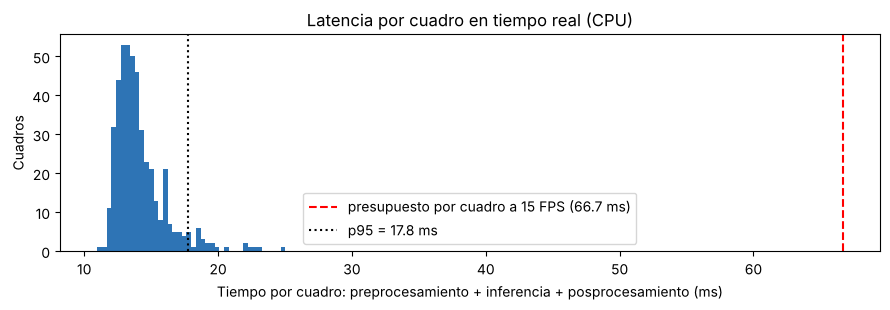

In [18]:
run_tr = sorted(Path("outputs").glob("*_tiempo-real"))[-1]
resumen_tr = json.loads((run_tr / "resumen.json").read_text(encoding="utf-8"))
print(json.dumps({k: resumen_tr[k] for k in ["fps_objetivo", "cuadros_recibidos", "procesadas", "cuadros_descartados",
      "fps_efectivo", "latencia_por_imagen", "fuera_de_presupuesto", "exactitud", "exactitud_suavizada",
      "vacios_marcados_inciertos"]}, ensure_ascii=False, indent=2))

tr = pd.read_csv(run_tr / "resultados.csv").drop(columns="clase_real").merge(
     pd.read_csv("data/video/figuras_etiquetas.csv"), on="cuadro")
presupuesto = 1000 / resumen_tr["fps_objetivo"]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(tr["total_ms"], bins=40, color="#2e74b5")
ax.axvline(presupuesto, color="red", ls="--", label=f"presupuesto por cuadro a 15 FPS ({presupuesto:.1f} ms)")
ax.axvline(tr["total_ms"].quantile(.95), color="black", ls=":", label=f"p95 = {tr['total_ms'].quantile(.95):.1f} ms")
ax.set_xlabel("Tiempo por cuadro: preprocesamiento + inferencia + posprocesamiento (ms)"); ax.set_ylabel("Cuadros")
ax.legend(); ax.set_title("Latencia por cuadro en tiempo real (CPU)")
plt.tight_layout(); plt.savefig(FIG / "05_latencia_tiempo_real.png", dpi=150); plt.show()

**Latencia:** cada cuadro tarda unos 14 ms (p50) y unos 20 ms en el p95, menos de un tercio del presupuesto de
66.7 ms. A 15 FPS no se perdió ningún cuadro y el procesador queda libre la mayor parte del tiempo. Se reportan la **mediana (p50)**, que es el
caso típico, y el **p95**, el tiempo que no se supera en el 95 % de los cuadros; en sistemas reales importa más el p95
que el promedio, porque los picos son los que provocan pérdidas.

### Prueba de estrés: ¿cuántos FPS soporta?

Repetimos con una "cámara" de **200 FPS** (presupuesto de 5 ms por cuadro), más rápida de lo que el pipeline puede atender:

In [19]:
!{sys.executable} src/pipeline_operativo.py --modo tiempo-real --entrada data/video/figuras.mp4 --fps 200
run_estres = sorted(Path("outputs").glob("*_tiempo-real"))[-1]
estres = json.loads((run_estres / "resumen.json").read_text(encoding="utf-8"))
print(f"\nRecibidos {estres['cuadros_recibidos']} | procesados {estres['procesadas']} | "
      f"descartados {estres['cuadros_descartados']} ({estres['cuadros_descartados'] / estres['cuadros_recibidos']:.0%}) | "
      f"FPS efectivos {estres['fps_efectivo']}")

I0000 00:00:1793474018.752884    5166 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793474020.014021    5166 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


13:13:41 | INFO    | === Ejecución 20261031-131341_tiempo-real ===
13:13:41 | INFO    | Huella SHA-256 verificada (06b88942d630...)


13:13:42 | INFO    | Modelo cargado: modelo_figuras_v1.keras v1.0.0 en 0.23 s
13:13:42 | INFO    | Dispositivo de ejecución: CPU


13:13:42 | INFO    | Prueba de integridad correcta (salida (1, 3), suma de probabilidades = 1.000)
13:13:42 | INFO    | Modo tiempo real: fuente 'data/video/figuras.mp4' (15 FPS de origen), objetivo 200.0 FPS = 5.0 ms por cuadro


13:13:44 | INFO    | Cuadros procesados 149 / descartados 307 | 64.9 FPS efectivos | p95 15.95 ms
13:13:44 | INFO    | Resultados en: /home/claude/maestria_modelo_vision_inteligente/outputs/20261031-131341_tiempo-real



Recibidos 456 | procesados 149 | descartados 307 (67%) | FPS efectivos 64.9


**Interpretación:** cuando los cuadros llegan más rápido de lo que se procesan, el sistema no se "atrasa" acumulando
cuadros viejos: **descarta** los que ya no alcanzó a ver y trabaja siempre con el más reciente. El número de FPS
efectivos es la **capacidad máxima** del pipeline en esta CPU, y será la línea base para comparar el despliegue
*edge* de la Actividad 4.2.

### ¿Qué tan bien clasifica el video?

In [20]:
figuras = tr[tr["clase_real"] != "ninguna"].copy()
figuras["cruda_con_umbral"] = figuras["clase"].where(figuras["estado"] == "ok", "incierto")

def desglose(col):
    ok = figuras[col] == figuras["clase_real"]; inc = figuras[col] == "incierto"
    return {"correcto": ok.mean(), "incierto (se abstiene)": inc.mean(), "incorrecto": (~ok & ~inc).mean(),
            "cambios_de_etiqueta": int((figuras[col] != figuras[col].shift()).sum())}

tabla_tr = pd.DataFrame({"Sin umbral": desglose("clase"),
                         "Con umbral 0.80": desglose("cruda_con_umbral"),
                         "Con umbral + suavizado (5 cuadros)": desglose("clase_suavizada")}).T
display(tabla_tr.style.format({c: "{:.1%}" for c in tabla_tr.columns[:3]}))

por_comp = figuras.assign(correcto=figuras["clase"] == figuras["clase_real"]) \
                  .groupby("comportamiento")["correcto"].mean().rename("exactitud (sin umbral)")
display(por_comp.to_frame().style.format("{:.1%}"))
vacios = tr[tr["clase_real"] == "ninguna"]
print(f"Cuadros SIN figura: confianza media {vacios['confianza'].mean():.1%}; "
      f"marcados como 'incierto' tras el suavizado: {(vacios['clase_suavizada'] == 'incierto').mean():.0%}")

,correcto,incierto (se abstiene),incorrecto,cambios_de_etiqueta
Sin umbral,90.8%,0.0%,9.2%,19.000000
Con umbral 0.80,88.3%,6.1%,5.6%,18.000000
Con umbral + suavizado (5 cuadros),81.7%,12.5%,5.8%,27.000000


,exactitud (sin umbral)
comportamiento,
entra_por_borde,63.3%
estatica,100.0%
gira,100.0%
se_mueve,100.0%


Cuadros SIN figura: confianza media 44.6%; marcados como 'incierto' tras el suavizado: 77%


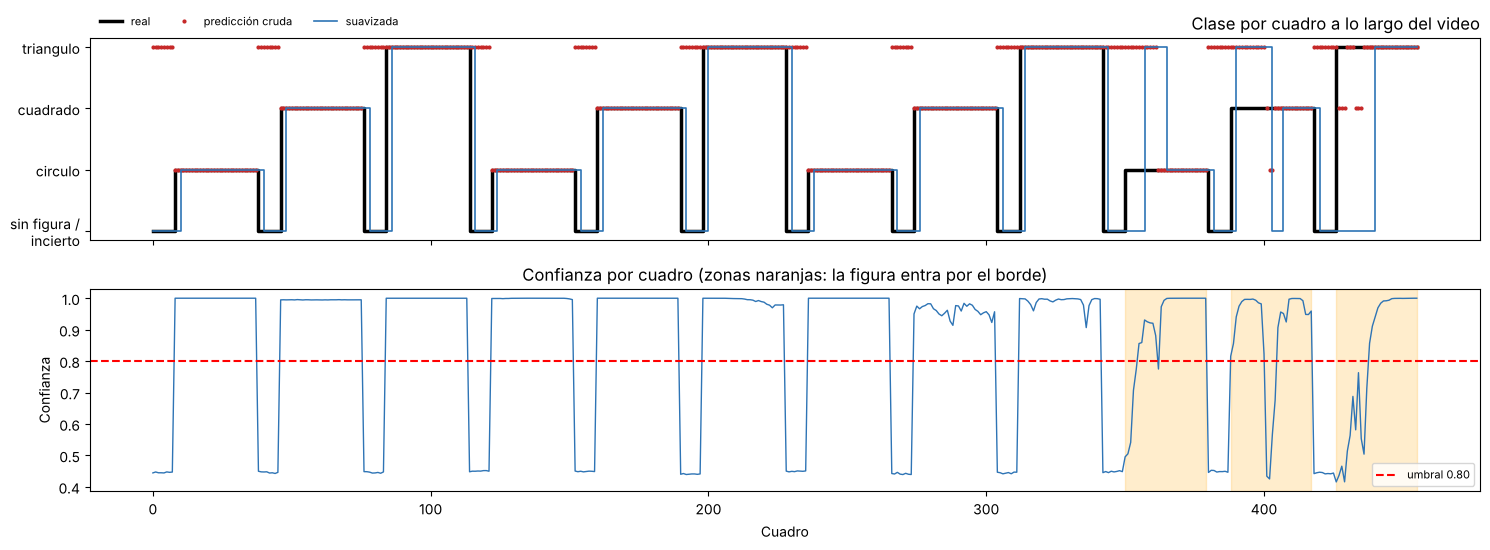

In [21]:
codigos = {"incierto": -1, **{c: i for i, c in enumerate(clases)}, "ninguna": -1}
fig, (a1, a2) = plt.subplots(2, 1, figsize=(15, 5.6), sharex=True)
a1.step(tr["cuadro"], tr["clase_real"].map(codigos), where="post", color="black", lw=2.5, label="real")
a1.plot(tr["cuadro"], tr["clase"].map(codigos), ".", color="#c62828", ms=4, label="predicción cruda")
a1.step(tr["cuadro"], tr["clase_suavizada"].map(codigos), where="post", color="#2e74b5", lw=1.2, label="suavizada")
a1.set_yticks([-1, 0, 1, 2], ["sin figura /\nincierto"] + clases)
a1.legend(ncol=3, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
a1.set_title("Clase por cuadro a lo largo del video", loc="right")
a2.plot(tr["cuadro"], tr["confianza"], color="#2e74b5", lw=1)
a2.axhline(cfg["postprocesamiento"]["umbral_confianza"], color="red", ls="--", label="umbral 0.80")
for _, g in tr[tr["comportamiento"] == "entra_por_borde"].groupby("escena"):
    a2.axvspan(g["cuadro"].min(), g["cuadro"].max(), color="orange", alpha=.2)
a2.set_ylabel("Confianza"); a2.set_xlabel("Cuadro"); a2.legend(fontsize=8, loc="lower right")
a2.set_title("Confianza por cuadro (zonas naranjas: la figura entra por el borde)")
plt.tight_layout(); plt.savefig(FIG / "06_linea_tiempo_video.png", dpi=150); plt.show()

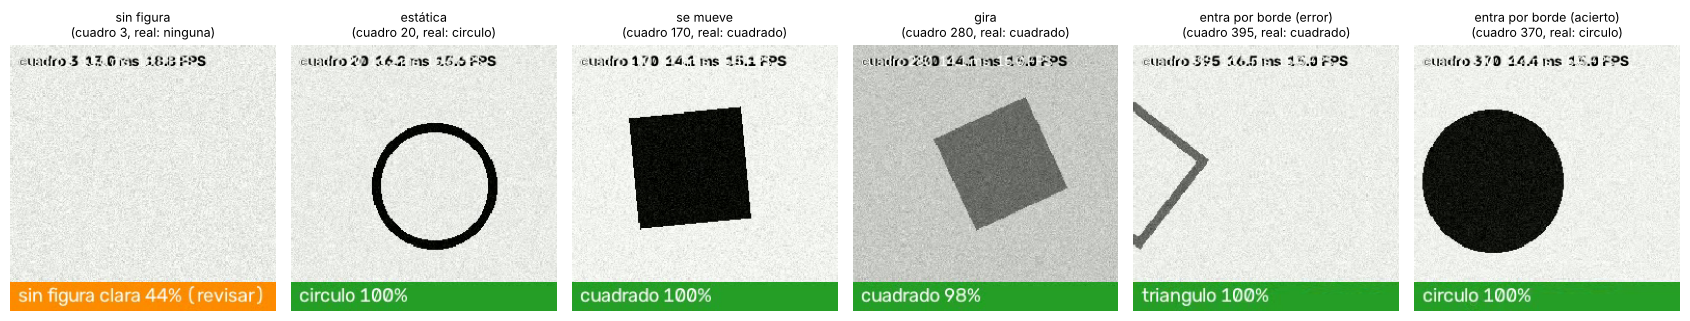

In [22]:
# Algunos cuadros del video anotado que generó el pipeline
captura = cv2.VideoCapture(str(run_tr / "video_anotado.mp4")); cuadros = []
while True:
    ok, c = captura.read()
    if not ok: break
    cuadros.append(c)
captura.release()
elegir = {"sin figura": 3, "estática": 20, "se mueve": 170, "gira": 280, "entra por borde (error)": 395, "entra por borde (acierto)": 370}
fig, ejes = plt.subplots(1, len(elegir), figsize=(17, 3.2))
for eje, (titulo, i) in zip(ejes, elegir.items()):
    eje.imshow(cv2.cvtColor(cuadros[i], cv2.COLOR_BGR2RGB)); eje.set_title(f"{titulo}\n(cuadro {i}, real: {tr.loc[i, 'clase_real']})", fontsize=9); eje.axis("off")
plt.tight_layout(); plt.savefig(FIG / "07_cuadros_video.png", dpi=150); plt.show()

**Interpretación crítica del video:**
* Con la figura **completa** (quieta, en movimiento o girando) la exactitud es del 100 %: el aumento de datos de la 3.3
  (rotaciones y traslaciones) hace al modelo indiferente a la posición y al giro.
* **Todos los errores** ocurren cuando la figura **entra por el borde**: un círculo cortado parece un triángulo o un
  cuadrado. El modelo nunca vio figuras incompletas al entrenar. La mitad de esos errores tienen confianza mayor a 85 %
  (algunos hasta 99.7 %), así que el umbral solo atrapa los más dudosos.
* En los cuadros **sin figura** la red responde siempre "triángulo", con ~45 % de confianza. Sin umbral, el sistema
  "vería" triángulos donde no hay nada; con el umbral de 0.80, el **100 %** de esos cuadros se marcan como dudosos.
* **Umbral:** baja los errores aceptados de 9.2 % a 5.6 % a cambio de abstenerse en el 6.1 % de los cuadros con figura.
* **Suavizado — un resultado negativo, pero útil:** en este video **no aporta**. Las predicciones de figuras completas
  ya eran perfectas y estables, así que no había "parpadeo" que corregir. El suavizado solo agregó costos:
  1. Un **retraso de 2 cuadros** (133 ms) al inicio de cada escena, que aparece como "incierto".
  2. **Más** cambios de etiqueta (27 contra 19) por esas transiciones.
  3. Los primeros cuadros vacíos de cada pausa todavía "heredan" votos de la figura anterior: solo el 77 % de los
     cuadros vacíos queda como incierto, contra 100 % con el umbral solo.

  El suavizado se justifica con cámaras reales, donde el ruido, el desenfoque o los reflejos hacen que la predicción
  cambie de un cuadro a otro. Por eso queda como **parámetro configurable** (`ventana_suavizado`): debe calibrarse con
  video de la cámara real, y con una fuente limpia como esta lo indicado es usar `1` (desactivado).

Es el compromiso típico de un sistema en tiempo real: **estabilidad contra velocidad de reacción**, y solo los datos
dicen cuál conviene.

## 10. ¿Qué umbral de confianza conviene?

El umbral es un **parámetro operativo** (vive en `config.yaml`) y se elige según el costo de cada tipo de error.
Con las predicciones del video calculamos, para cada umbral, qué fracción de cuadros con figura se **aceptan con
error**, cuántos se **dejan de clasificar**, y cuántos cuadros **vacíos** se aceptan como si tuvieran figura.

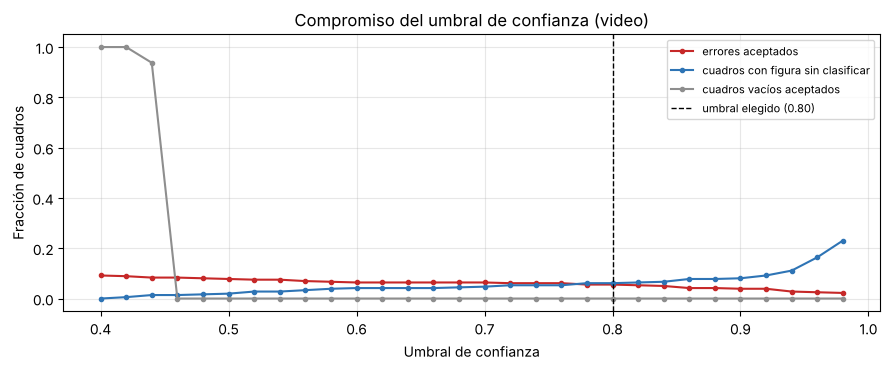

umbral,errores aceptados,cuadros con figura sin clasificar,cuadros vacíos aceptados
0.500000,7.8%,1.9%,0.0%
0.700000,6.4%,4.7%,0.0%
0.800000,5.6%,6.1%,0.0%
0.900000,3.9%,8.1%,0.0%
0.960000,2.5%,16.4%,0.0%


In [23]:
umbrales = np.round(np.arange(0.40, 1.00, 0.02), 2)
curva = []
for u in umbrales:
    acepta = figuras["confianza"] >= u
    curva.append({"umbral": u,
                  "errores aceptados": (acepta & (figuras["clase"] != figuras["clase_real"])).mean(),
                  "cuadros con figura sin clasificar": (~acepta).mean(),
                  "cuadros vacíos aceptados": (vacios["confianza"] >= u).mean()})
curva = pd.DataFrame(curva)
fig, ax = plt.subplots(figsize=(9, 3.8))
for col, color in zip(curva.columns[1:], ["#c62828", "#2e74b5", "#8e8e8e"]):
    ax.plot(curva["umbral"], curva[col], "o-", ms=3, label=col, color=color)
ax.axvline(cfg["postprocesamiento"]["umbral_confianza"], color="black", ls="--", lw=1, label="umbral elegido (0.80)")
ax.set_xlabel("Umbral de confianza"); ax.set_ylabel("Fracción de cuadros"); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title("Compromiso del umbral de confianza (video)")
plt.tight_layout(); plt.savefig(FIG / "08_umbral_confianza.png", dpi=150); plt.show()
display(curva[curva["umbral"].isin([0.5, 0.7, 0.8, 0.9, 0.96])].style.format("{:.1%}", subset=curva.columns[1:]).hide(axis="index"))

**Interpretación:** subir el umbral por encima de ~0.46 elimina de golpe los cuadros vacíos aceptados, porque la red
responde ahí con una confianza muy baja y constante. A partir de ahí, subirlo más reduce poco a poco los errores
aceptados, pero deja sin clasificar cada vez más cuadros buenos. **0.80** es un punto razonable: no acepta cuadros
vacíos, reduce los errores aceptados en ~40 % (de 9.2 % a 5.6 %) y deja sin clasificar solo el 6 % de los cuadros
con figura. Subirlo a 0.96 bajaría los errores a 2.5 %, pero dejaría sin clasificar el 16 %. En una operación real, el umbral se
ajustaría según qué sea más caro: un error o una revisión manual.

## 11. Fase 9: registro y auditoría

Cada ejecución dejó un **log detallado** y una línea en la **bitácora de ejecuciones**. Con ella se puede auditar
qué versión del modelo se usó, cuántas imágenes se procesaron, cuántas fallaron y qué tan rápido fue.

In [24]:
display(pd.read_csv("outputs/registro_ejecuciones.csv").style.hide(axis="index"))
print(f"\nPrimeras líneas del log {run_tr.name}.log:\n")
print("\n".join((Path("outputs/logs") / f"{run_tr.name}.log").read_text(encoding="utf-8").splitlines()[:8]))

run_id,modo,entrada,version_modelo,procesadas,errores,exactitud,latencia_p50_ms,duracion_s
20261031-131232_imagen,imagen,data/ejemplos/variaciones/cuadrado_transparente.png,1.0.0,1,0,nan,13.780000,nan
20261031-131236_lote,lote,data/conjunto_prueba,1.0.0,180,0,0.994400,0.670000,0.180000
20261031-131229_notebook,lote,data/ejemplos,1.0.0,28,4,nan,2.230000,0.140000
20261031-131306_tiempo-real,tiempo-real,data/video/figuras.mp4,1.0.0,456,0,0.908300,13.620000,30.350000
20261031-131341_tiempo-real,tiempo-real,data/video/figuras.mp4,1.0.0,149,0,nan,11.760000,2.290000



Primeras líneas del log 20261031-131306_tiempo-real.log:

2026-10-31 13:13:06,563 | INFO    | === Ejecución 20261031-131306_tiempo-real ===
2026-10-31 13:13:06,568 | INFO    | Huella SHA-256 verificada (06b88942d630...)
2026-10-31 13:13:06,796 | INFO    | Modelo cargado: modelo_figuras_v1.keras v1.0.0 en 0.23 s
2026-10-31 13:13:06,796 | INFO    | Dispositivo de ejecución: CPU
2026-10-31 13:13:06,854 | INFO    | Prueba de integridad correcta (salida (1, 3), suma de probabilidades = 1.000)
2026-10-31 13:13:06,858 | INFO    | Modo tiempo real: fuente 'data/video/figuras.mp4' (15 FPS de origen), objetivo 15.0 FPS = 66.7 ms por cuadro
2026-10-31 13:13:37,209 | INFO    | Cuadros procesados 456 / descartados 0 | 15.0 FPS efectivos | p95 17.76 ms | exactitud 90.83% (suavizada 81.67%)
2026-10-31 13:13:37,209 | INFO    | Resultados en: /home/claude/maestria_modelo_vision_inteligente/outputs/20261031-131306_tiempo-real


## 12. Conclusiones

1. **El pipeline reproduce exactamente al modelo de la Unidad 3** (99.44 %, mismas probabilidades). La paridad es la
   primera prueba que debe pasar cualquier despliegue.
2. **El preprocesamiento es la parte más delicada.** Un detalle distinto (otra normalización, colores invertidos, baja
   resolución) cuesta de 1 a 9 puntos de exactitud **sin producir ningún error visible** y sin que la confianza avise.
   Por eso se centralizó en un módulo y se documentó en la ficha técnica.
3. **El código de producción es defensivo:** valida archivos, verifica la huella del modelo, hace una prueba de
   integridad, registra los errores y sigue trabajando.
4. **Lote y tiempo real son compromisos distintos:** el lote multiplica por más de 30 las imágenes por segundo; el
   tiempo real minimiza la latencia de cada cuadro (14 ms) y descarta los que no alcanza a procesar. En el modo lote, el
   cuello de botella es leer y preparar archivos, no el modelo.
5. **El análisis del video revela los límites del modelo:** figuras parciales y objetos que no pertenecen a ninguna
   clase. El umbral mitiga parte del problema. El suavizado no ayudó con esta fuente y debe calibrarse con la cámara
   real. La solución de fondo está en los datos de entrenamiento (figuras parciales, una clase "otro").

**Siguiente paso (Actividad 4.2):** empaquetar este mismo pipeline en un contenedor Docker, convertir el modelo a un
formato ligero para dispositivos *edge* y medir su rendimiento con recursos limitados.